# Machine-learned noise selection and noise PSD templates, Run 76 (local and global)

**Project.** The optimal filter (OF) needs a *noise template*: the power spectral density $J(f)$ of the detector noise, estimated from traces that hold **only** noise. The current method (`clean_randoms`, Note 9, after Notes 2 and 2a) keeps a random trigger if its `Side2pA` trace is quiet: a band in the excursion ratio and `log10(bstd) < 0.5`. In this dump it keeps 101 of the 1008 randoms. Hand cuts throw away good traces, and they can let through traces with small pulses or tails, which raise the low-frequency end of the PSD.

This notebook:

1. loads one dump and builds **time-domain and frequency-domain features** for every trace of the six sensor channels;
2. trains a **machine-learning classifier** of good and bad noise traces. There are no hand labels, so it is *semi-supervised*: confident seeds from conservative cuts, plus **simulated bad traces** (real pulses, spikes and drifts injected into good noise traces), whose truth is known. It is trained on every event (the triggered events supply real pulses);
3. **measures** how well each method classifies (the current cut, an unsupervised Isolation Forest as in `legacy/MLmodelImplementaion.ipynb`, and the new classifier): the share of clean traces kept, and the share of injected pulses rejected as a function of their size;
4. builds the **noise PSD template** from the **random triggers** each method accepts and compares the templates, including the optimal-filter resolution each one gives on randoms it has not seen;
5. builds **local templates** (blocks of the dump, and a rolling template around each trace) and tests whether they hold information the dump-wide template misses;
6. saves the templates to HDF5.

**Conventions** (same as the library and Note 9): one-sided PSD $S(f) = \frac{2\,\Delta t}{N}|X_k|^2$ in counts²/Hz, no factor 2 at DC and Nyquist, baseline-subtracted (pretrigger mean) and with the 10 glitch samples dropped. Golwala's thesis (the *Optimal Filter Reference* in `legacy/`) writes the two-sided $J = S/2$; the OF resolution below is computed consistently with $S$.

**The data.** Series `07221203_2025`, dump `F0001`, Run 76 at the University of Minnesota (PuBe neutron source, Side-2 readout): the dump of Notes 2, 2a and 9. The readout is the library's `DCRC_RUN76`: 0.8 µs per sample, a 500-sample baseline window, 10 glitch samples. The channels are the six sensors of `goldpan.channels.sensor_channels()` (`Side2pA` to `Side2pF`); DCRC4 pA, dump channel (2, 0), is the NaI trigger input and is left out.

**Two assumptions of the library, both marked under development:** the random-trigger label (`cuts.randoms`: events recorded as `Physics` are taken to be the randoms, Note 2a) and the channel map (`goldpan.channels`). This notebook was adapted from `noise-template-ml-george.ipynb` (series `07180827_0000`, commit `1f80598`), which was written with Claude Code.


In [1]:
from pathlib import Path
import time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import h5py
from sklearn.ensemble import HistGradientBoostingClassifier, IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score
from nsdf_dark_matter.idx import load_all_data

from goldpan import quantities as q, cuts, operations as op, io, channels
from goldpan.config import PulseConfig
import check_environment
check_environment.check()

DUMP = "07221203_2025_F0001"
SAMPLE_PERIOD_S = 0.8e-6          # the Run 76 phonon readout (registry: DCRC_RUN76)
PRETRIGGER = 500                  # the Run 76 baseline window (registry: DCRC_RUN76)
CONFIG = PulseConfig(pretrigger_samples=PRETRIGGER, glitch_samples=10, sample_period_s=SAMPLE_PERIOD_S)
# The traces below are stored baseline-subtracted with the glitch samples already dropped, so the library
# functions see them through this config: the pretrigger is 490 samples and nothing more is skipped.
CONFIG_P = PulseConfig(pretrigger_samples=PRETRIGGER - CONFIG.glitch_samples, glitch_samples=0, sample_period_s=SAMPLE_PERIOD_S)

import warnings
warnings.filterwarnings("ignore", message=".*under_development.*")   # randoms and the channel map: see the introduction
RNG = np.random.default_rng(76)
# one colour per method, used in every figure
COLOUR = {"current cut": "#eb6834", "ML classifier": "#2a78d6", "Isolation Forest": "#1baf7a", "seed good": "#52514e"}
DIVERGING = LinearSegmentedColormap.from_list("blue_grey_orange", ["#2a78d6", "#f0efec", "#eb6834"])
FIG = Path("figures"); FIG.mkdir(exist_ok=True)

  - goldpan is 0.1.0, but requirements.txt wants 0.2.0.
  This is only a warning, and you can keep working. To fix it, follow 'Updating your setup': https://villano-lab.github.io/NSDF-Data/#maintenance


## 1. Load the dump

Each event has detectors 0, 1 and 2 (the boards DCRC1, DCRC3 and DCRC4), four inputs each, 4096 samples. Only the six sensor channels are kept. All traces are read once into memory (as `float32`, baseline-subtracted, glitch samples dropped). The random triggers are found with `cuts.randoms` (see the introduction).


In [2]:
t0 = time.time()
cdms = load_all_data(str(Path.home() / "idx" / DUMP))
all_ids = cdms.get_detector_ids()
# The six sensors of the Side-2 readout; DCRC4 pA, dump channel (2, 0), is the NaI trigger input and is left out.
SENSORS = [(c.detector, c.channel) for c in channels.sensor_channels()]
detectors = sorted({d for d, _ in SENSORS})
det_ids = {det: io.filter_by_detector(all_ids, det) for det in detectors}

# every detector must list the same events in the same order
event_numbers = np.array([int(io.event_id(i)) for i in det_ids[detectors[0]]])
for det in detectors[1:]:
    assert np.array_equal(event_numbers, [int(io.event_id(i)) for i in det_ids[det]])
n_events = len(event_numbers)

# global timestamps (1 s resolution) from the dump's .csv
csv = np.genfromtxt(Path.home() / "idx" / DUMP / f"{DUMP}.csv", delimiter=",", names=True, dtype=None, encoding="utf-8")
ts_by_event = dict(zip(csv["event"], csv["global_timestamp"]))
timestamps = np.array([ts_by_event[e] for e in event_numbers]) - min(ts_by_event.values())

trigger_types = np.asarray(io.trigger_types(cdms, det_ids[detectors[0]]))
IS_RANDOM = cuts.randoms(trigger_types)          # events recorded as 'Physics', taken to be the random triggers
print("trigger types:", {str(k): int(v) for k, v in zip(*np.unique(trigger_types, return_counts=True))},
      f"-> {IS_RANDOM.sum()} randoms")

raw_traces = {}      # (det, ch) -> processed traces, float32, shape (events, 4086)
dead = []
for det in detectors:
    block = np.stack([cdms.get_detector_channels(i) for i in det_ids[det]]).astype(np.float32)   # (events, 4, 4096); raw is uint16
    for ch in range(block.shape[1]):
        if (det, ch) not in SENSORS:
            continue
        x = block[:, ch, :]
        if cuts.dead_channel(x, CONFIG).mean() > 0.5:         # not read out in most events
            dead.append((det, ch))
            continue
        raw_traces[(det, ch)] = op.trim_glitch(op.baseline_subtract(x, CONFIG), CONFIG).astype(np.float32)
    del block
KEYS = list(raw_traces)
NAME = {key: channels.channel_name(*key) for key in KEYS}
N_SAMP = raw_traces[KEYS[0]].shape[1]
print(f"{n_events} events over {timestamps.max()} s; sensor channels {[f'{NAME[k]} {k}' for k in KEYS]}; dead {dead}")
print(f"{N_SAMP} samples per trace after the glitch, loaded in {time.time() - t0:.0f} s")


trigger types: {'Physics': 1008, 'Unknown': 509} -> 1008 randoms


1517 events over 58 s; sensor channels ['Side2pC (0, 0)', 'Side2pF (0, 1)', 'Side2pE (0, 3)', 'Side2pB (1, 0)', 'Side2pA (1, 1)', 'Side2pD (1, 3)']; dead []
4086 samples per trace after the glitch, loaded in 1 s


### 1.1 What the traces look like

The largest deviation from the pretrigger mean separates traces that hold a pulse from traces that look like noise. Below, for one channel: its distribution for the randoms and for the other (triggered) events, and a few traces of each.


Side2pC (0, 0): median max |deviation| 12.3 counts in the 1008 randoms, 190.6 counts in the 509 other events


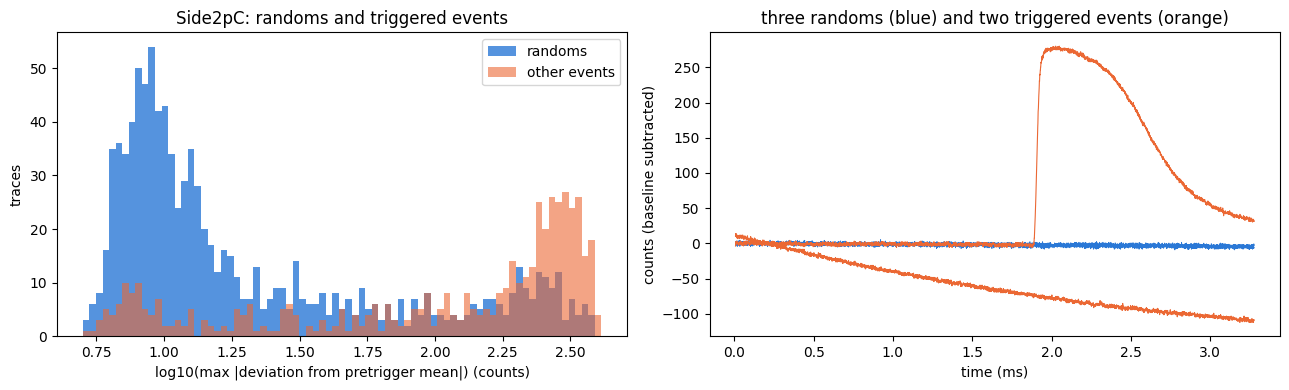

In [3]:
key0 = KEYS[0]
x = raw_traces[key0]
maxdev = np.abs(x).max(axis=1)
print(f"{NAME[key0]} {key0}: median max |deviation| {np.median(maxdev[IS_RANDOM]):.1f} counts in the {IS_RANDOM.sum()} randoms, "
      f"{np.median(maxdev[~IS_RANDOM]):.1f} counts in the {(~IS_RANDOM).sum()} other events")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
bins = np.linspace(np.log10(maxdev.min()), np.log10(maxdev.max()), 80)
axes[0].hist(np.log10(maxdev[IS_RANDOM]), bins=bins, color=COLOUR["ML classifier"], alpha=0.8, label="randoms")
axes[0].hist(np.log10(maxdev[~IS_RANDOM]), bins=bins, color=COLOUR["current cut"], alpha=0.6, label="other events")
axes[0].set_xlabel("log10(max |deviation from pretrigger mean|) (counts)"); axes[0].set_ylabel("traces")
axes[0].set_title(f"{NAME[key0]}: randoms and triggered events"); axes[0].legend()
t_ms = (np.arange(N_SAMP) + CONFIG.glitch_samples) * SAMPLE_PERIOD_S * 1e3
for i in np.flatnonzero(IS_RANDOM)[:3]:
    axes[1].plot(t_ms, x[i], lw=0.6, color=COLOUR["ML classifier"])
for i in np.flatnonzero(~IS_RANDOM)[:2]:
    axes[1].plot(t_ms, x[i], lw=0.8, color=COLOUR["current cut"])
axes[1].set_xlabel("time (ms)"); axes[1].set_ylabel("counts (baseline subtracted)")
axes[1].set_title("three randoms (blue) and two triggered events (orange)")
fig.tight_layout(); plt.savefig(FIG / f"ml-noise-traces-{DUMP}.png", dpi=110); plt.show()


## 2. Features of every trace

Each trace is described by numbers that a person would look at, so that the classifier's choices can be checked by eye.

**Time domain** (σ is the pretrigger standard deviation, `bstd`):

| feature | catches |
|---|---|
| `log_bstd`, `log_std_post` | a noisy or contaminated pretrigger; a pulse after the trigger |
| `log_maxdev_pre`, `log_maxdev_post` | the largest excursion before and after the trigger (library: `max_deviation`) |
| `log_ratio` | `log_excursion_ratio`, the quantity of the current cut |
| `smooth_peak` | the largest excursion of a 50-sample running mean, in units of σ/√50: small slow pulses that hide in the sample-to-sample noise |
| `drift`, `slope` | the end of the trace minus the start, and a straight-line slope, in units of σ: tails of earlier pulses |
| `spike` | the largest sample-to-sample jump over its own scatter: glitches |
| `skew`, `kurt` | asymmetry and heavy tails of the sample distribution |

**Frequency domain** (per-trace one-sided PSD, compared with the channel's median PSD, which is robust to the half of traces that hold pulses):

| feature | catches |
|---|---|
| `band_k` (8 log-spaced bands, 300 Hz to 625 kHz) | log10 of the trace's power over the median power in each band: pulses and tails put power at low frequency |
| `psd_peak` | the largest single-bin excess: a line or a burst at one frequency |
| `psd_mean_log` | the mean log excess over all bins (an overall noise level) |

**Optimal filter**: `of_trig` and `of_peak` (section 2.2).

**Across channels**: `other_smooth`, `other_maxdev` and `other_of`, the largest `smooth_peak`, `log_maxdev_post` and `of_peak` in the other working channels of the same event. A real pulse shows up in several channels at once.

Before going into the classifier the features are put on a common scale (section 2.3).

In [4]:
BAND_EDGES = np.geomspace(300, 1 / (2 * SAMPLE_PERIOD_S), 9)
FREQS = q.frequencies_hz(N_SAMP, CONFIG_P)
BAND_BINS = [(FREQS >= lo) & (FREQS < hi) for lo, hi in zip(BAND_EDGES[:-1], BAND_EDGES[1:])]
TIME_FEATURES = ["log_bstd", "log_std_post", "log_maxdev_pre", "log_maxdev_post", "log_ratio",
                 "smooth_peak", "drift", "slope", "spike", "skew", "kurt"]
FREQ_FEATURES = [f"band_{k}" for k in range(len(BAND_BINS))] + ["psd_peak", "psd_mean_log"]
OF_FEATURES = ["of_peak", "of_trig"]
CROSS_FEATURES = ["other_smooth", "other_maxdev", "other_of"]
FEATURES = TIME_FEATURES + FREQ_FEATURES + OF_FEATURES + CROSS_FEATURES
KBINS = slice(1, len(FREQS) - 1)        # positive frequencies without DC and Nyquist


def one_sided_psd(traces):
    # One-sided PSD (counts^2/Hz) of each trace: (2 dt / N) |X_k|^2, without the factor 2 at DC and Nyquist.
    n = traces.shape[-1]
    psd = q.power_spectrum(traces, CONFIG_P) * (SAMPLE_PERIOD_S / n)
    psd[..., 1:(n + 1) // 2 if n % 2 else n // 2] *= 2
    return psd


def channel_features(x, ref_psd=None, chunk=1000):
    # Time- and frequency-domain features of a batch of processed traces (events, samples), as a dict of arrays.
    # ref_psd: the channel's median PSD; computed from this batch if not given (pass it for injected traces).
    pre = x[:, :CONFIG_P.pretrigger_samples]
    post = x[:, CONFIG_P.pretrigger_samples:]
    bstd = np.maximum(pre.std(axis=1), 1e-3)
    f = {}
    f["log_bstd"] = np.log10(bstd)
    f["log_std_post"] = np.log10(np.maximum(post.std(axis=1), 1e-3))
    f["log_maxdev_pre"] = np.log10(np.abs(pre).max(axis=1) + 1e-3)
    f["log_maxdev_post"] = np.log10(q.max_deviation(x, CONFIG_P) + 1e-3)
    f["log_ratio"] = np.log10(q.max_deviation(x, CONFIG_P) / bstd + 1e-6)
    w = 50
    c = np.cumsum(np.pad(x, ((0, 0), (1, 0))), axis=1, dtype=np.float64)
    smooth = (c[:, w:] - c[:, :-w]) / w
    f["smooth_peak"] = np.abs(smooth).max(axis=1) / (bstd / np.sqrt(w))
    f["drift"] = (x[:, -500:].mean(axis=1) - pre.mean(axis=1)) / bstd
    t = np.arange(x.shape[1]) - (x.shape[1] - 1) / 2
    f["slope"] = (x @ t) / (t @ t) * x.shape[1] / bstd
    d = np.diff(x, axis=1)
    f["spike"] = np.abs(d).max(axis=1) / np.maximum(d.std(axis=1), 1e-3)
    z = (x - x.mean(axis=1, keepdims=True)) / np.maximum(x.std(axis=1, keepdims=True), 1e-3)
    f["skew"] = (z ** 3).mean(axis=1)
    f["kurt"] = (z ** 4).mean(axis=1) - 3
    psd = np.concatenate([one_sided_psd(x[i:i + chunk]) for i in range(0, len(x), chunk)])
    if ref_psd is None:
        ref_psd = np.median(psd, axis=0)
    rel = np.maximum(psd[:, 1:-1] / ref_psd[1:-1], 1e-12)
    for k, b in enumerate(BAND_BINS):
        f[f"band_{k}"] = np.log10(psd[:, b].mean(axis=1) / ref_psd[b].mean())
    f["psd_peak"] = np.log10(rel.max(axis=1))
    f["psd_mean_log"] = np.log(rel).mean(axis=1)
    return f, ref_psd


def add_cross_features(feats):
    # feats: {key: dict of arrays over the same events}. Adds the largest value in the other channels.
    for key in feats:
        others = [k for k in feats if k != key]
        feats[key]["other_smooth"] = np.max([feats[k]["smooth_peak"] for k in others], axis=0)
        feats[key]["other_maxdev"] = np.max([feats[k]["log_maxdev_post"] for k in others], axis=0)
        feats[key]["other_of"] = np.max([feats[k]["of_peak"] for k in others], axis=0)
    return feats


t0 = time.time()
feats, REF_PSD, NOISE_SIGMA = {}, {}, {}
for key in KEYS:
    feats[key], REF_PSD[key] = channel_features(raw_traces[key])
    bstd = 10 ** feats[key]["log_bstd"]
    NOISE_SIGMA[key] = np.median(bstd[bstd < 3 * np.percentile(bstd, 10)])      # typical noise of the channel
    print(f"{key}: typical noise sigma {NOISE_SIGMA[key]:.2f} counts")
print(f"time and frequency features of {len(KEYS)} x {n_events} traces in {time.time() - t0:.0f} s")

(0, 0): typical noise sigma 1.53 counts


(0, 1): typical noise sigma 1.67 counts


(0, 3): typical noise sigma 1.60 counts


(1, 0): typical noise sigma 2.56 counts


(1, 1): typical noise sigma 2.18 counts


(1, 3): typical noise sigma 2.58 counts
time and frequency features of 6 x 1517 traces in 5 s


### 2.1 The pulse shape of each channel

Averaged from large but unsaturated pulses (100 to 2000 counts) that start at the trigger (raw onset sample 500 to 540) on a quiet pretrigger. Each is divided by its peak before averaging, and the average is scaled to a peak of 1. The same shape is the signal template $s(t)$ of the optimal filter, here and in section 5.

Side2pC (0, 0): pulse shape from 276 pulses
Side2pF (0, 1): pulse shape from 59 pulses
Side2pE (0, 3): pulse shape from 167 pulses
Side2pB (1, 0): pulse shape from 87 pulses
Side2pA (1, 1): pulse shape from 69 pulses
Side2pD (1, 3): pulse shape from 84 pulses


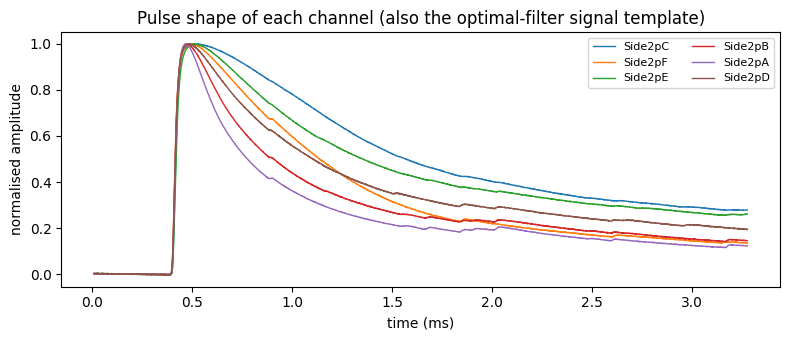

In [5]:
PULSE = {}
for key in KEYS:
    x = raw_traces[key]
    peak = x.max(axis=1)
    on = np.argmax(x > 0.2 * peak[:, None], axis=1) + CONFIG.glitch_samples
    ok = ((peak > 100) & (peak < 2000) & (on >= 500) & (on <= 540)
          & (10 ** feats[key]["log_bstd"] < 1.5 * NOISE_SIGMA[key]))
    shape = (x[ok] / peak[ok, None]).mean(axis=0)
    PULSE[key] = shape / shape.max()
    print(f"{NAME[key]} {key}: pulse shape from {ok.sum()} pulses")

fig, ax = plt.subplots(figsize=(8, 3.5))
for i, key in enumerate(KEYS):
    ax.plot(t_ms, PULSE[key], lw=1, label=NAME[key])
ax.set_xlabel("time (ms)"); ax.set_ylabel("normalised amplitude"); ax.legend(fontsize=8, ncol=2)
ax.set_title("Pulse shape of each channel (also the optimal-filter signal template)")
fig.tight_layout(); plt.show()

### 2.2 Optimal-filter features

The most sensitive detector of a small pulse of known shape in noise of known spectrum *is* the optimal filter. So the OF itself provides two features: the trace is filtered with the pulse shape and a **preliminary** noise PSD (the mean of a small, very strict set of quiet traces), giving the fitted amplitude $\hat A(\tau)$ for every start time $\tau$ (section 5 has the formula; here as a circular cross-correlation, all shifts at once with one FFT).

| feature | catches |
|---|---|
| `of_trig` | $\hat A$ at the trigger time, in units of its expected noise spread $\sigma_A$ (signed) |
| `of_peak` | the largest $|\hat A(\tau)|/\sigma_A$ over all start times: a small pulse anywhere in the trace |

and `other_of`, the largest `of_peak` in the other channels of the event. For pure noise `of_peak` is about 3 to 4 (the largest of ~4000 correlated values).

In [6]:
def of_setup(key, J):
    # Frequency-domain OF weights for the pulse shape of `key` and noise PSD J; also the norm and sigma_A.
    S = np.fft.rfft(PULSE[key])
    W = np.zeros_like(S)
    W[KBINS] = np.conj(S[KBINS]) / J[KBINS]
    norm = np.sum(np.abs(S[KBINS]) ** 2 / J[KBINS])
    return W, norm, np.sqrt(N_SAMP / (4 * SAMPLE_PERIOD_S * norm))


def of_features(key, x, chunk=1000):
    # A(tau) for every start time: sum_k Re(W_k V_k e^{2 pi i k tau / N}) / norm = irfft(W V) * N/2 / norm
    W, norm, sigma = OF_SETUP[key]
    peak, trig = [], []
    for i in range(0, len(x), chunk):
        A = np.fft.irfft(np.fft.rfft(x[i:i + chunk], axis=1) * W, n=N_SAMP, axis=1) * (N_SAMP / 2) / norm
        peak.append(np.abs(A).max(axis=1) / sigma)
        trig.append(A[:, 0] / sigma)
    return {"of_peak": np.concatenate(peak), "of_trig": np.concatenate(trig)}


OF_SETUP, PRELIM_PSD = {}, {}
for key in KEYS:
    f = feats[key]
    bstd = 10 ** f["log_bstd"]
    quiet = bstd < 1.2 * NOISE_SIGMA[key]
    # a strict preliminary selection, only for the preliminary PSD: quiet, flat, no excursion, no slow bump
    strict = (quiet & (f["log_ratio"] < 0.65) & (np.abs(f["drift"]) < 2)
              & (f["smooth_peak"] < np.median(f["smooth_peak"][quiet])))
    J0 = one_sided_psd(raw_traces[key][strict]).mean(axis=0)
    PRELIM_PSD[key] = J0
    OF_SETUP[key] = of_setup(key, J0)
    feats[key].update(of_features(key, raw_traces[key]))
    print(f"{key}: preliminary PSD from {strict.sum()} strict traces, sigma_A = {OF_SETUP[key][2]:.2f} counts; "
          f"median of_peak {np.median(feats[key]['of_peak'][strict]):.2f} in them")
feats = add_cross_features(feats)
print(f"{len(FEATURES)} features in all")

(0, 0): preliminary PSD from 96 strict traces, sigma_A = 0.58 counts; median of_peak 3.50 in them


(0, 1): preliminary PSD from 67 strict traces, sigma_A = 0.71 counts; median of_peak 3.05 in them


(0, 3): preliminary PSD from 73 strict traces, sigma_A = 0.65 counts; median of_peak 3.19 in them


(1, 0): preliminary PSD from 110 strict traces, sigma_A = 0.87 counts; median of_peak 3.23 in them


(1, 1): preliminary PSD from 34 strict traces, sigma_A = 1.06 counts; median of_peak 3.12 in them


(1, 3): preliminary PSD from 128 strict traces, sigma_A = 0.93 counts; median of_peak 3.32 in them
26 features in all


### 2.3 A common scale for the features

Every feature is put on a common scale for each channel, so that a value of 5 means "5 spreads away from typical noise" in every channel and one model can be trained on all channels together. The median and spread (1.4826 × the median absolute deviation) come from:

- for the time- and frequency-domain features: the channel's *core*, the traces with σ below 1.5 times the channel's typical noise; for the cross-channel ones, the events that are in the core of every channel;
- for the OF features: **simulated pure Gaussian noise** with the preliminary PSD. The core cannot be used for them: it holds many small pulses at the trigger (next paragraph), and their median and spread would hide exactly what these features are for.

**Why the trigger matters here.** Every event in this dump is a *trigger* (there are no random triggers), so a trace that looks like noise is usually an event whose triggering pulse was small or in another channel. For pure noise `of_trig` is centred on 0 with a spread of 1; in the quiet core it is not (printed below). The simulation also checks the OF arithmetic: in simulated noise `of_trig` must have a spread of 1.

In [7]:
def simulate_noise(J, n, rng):
    # n traces of stationary Gaussian noise whose one-sided PSD is J: E|X_k|^2 = J_k N / (2 dt), random phases.
    amp = np.sqrt(J * N_SAMP / (2 * SAMPLE_PERIOD_S))
    X = (rng.standard_normal((n, len(J))) + 1j * rng.standard_normal((n, len(J)))) * amp / np.sqrt(2)
    X[:, 0] = 0; X[:, -1] = 0
    return np.fft.irfft(X, n=N_SAMP, axis=1).astype(np.float32)


rng_sim = np.random.default_rng(1)
SIM_OF = {key: of_features(key, simulate_noise(PRELIM_PSD[key], 4000, rng_sim)) for key in KEYS}
for key in KEYS:
    SIM_OF[key]["other_of"] = np.max([SIM_OF[k]["of_peak"] for k in KEYS if k != key], axis=0)


def robust(v):
    med = np.median(v)
    mad = 1.4826 * np.median(np.abs(v - med))
    return med, (mad if mad > 0 else 1.0)


all_core = np.all([10 ** feats[k]["log_bstd"] < 1.5 * NOISE_SIGMA[k] for k in KEYS], axis=0)
SCALE = {}
print(f"{'channel':<9}{'core':>6}{'sim of_trig mean, std':>24}{'sim of_peak median':>20}{'core of_trig mean':>19}{'core share of_trig > 3':>24}")
for key in KEYS:
    core = 10 ** feats[key]["log_bstd"] < 1.5 * NOISE_SIGMA[key]
    SCALE[key] = {}
    for name in FEATURES:
        if name in OF_FEATURES or name == "other_of":
            SCALE[key][name] = robust(SIM_OF[key][name])
        elif name.startswith("other"):
            SCALE[key][name] = robust(feats[key][name][all_core])
        else:
            SCALE[key][name] = robust(feats[key][name][core])
    st = SIM_OF[key]["of_trig"]; ct = feats[key]["of_trig"][core]
    print(f"{str(key):<9}{core.sum():>6}{st.mean():>12.2f}, {st.std():<11.2f}{np.median(SIM_OF[key]['of_peak']):>20.2f}"
          f"{ct.mean():>19.2f}{(ct > 3).mean():>24.1%}")


def scaled_matrix(key, f):
    X = np.column_stack([(f[n] - SCALE[key][n][0]) / SCALE[key][n][1] for n in FEATURES])
    return np.clip(np.nan_to_num(X, nan=0.0), -1e4, 1e4)     # a dead trace in one event must not break the fit


X_all = {key: scaled_matrix(key, feats[key]) for key in KEYS}

channel    core   sim of_trig mean, std  sim of_peak median  core of_trig mean  core share of_trig > 3
(0, 0)     1302        0.03, 0.99                       2.92             104.23                   35.2%
(0, 1)      964        0.01, 1.01                       2.82              43.04                   15.5%
(0, 3)     1130       -0.00, 1.01                       2.92              79.54                   27.1%
(1, 0)     1028       -0.00, 0.98                       2.87              64.46                   19.0%
(1, 1)      969        0.03, 1.00                       2.82              56.40                   15.6%
(1, 3)     1033       -0.01, 0.99                       2.92              48.31                   18.9%


## 3. Labels: confident seeds and simulated bad traces

**Seeds.** A trace is a *seed good* if every time-domain feature, both OF features and the cross-channel features are within 3 spreads of typical noise; it is a *seed bad* if it is obviously not noise (an excursion, a running-mean peak or an OF peak more than 15 spreads out, or a pretrigger σ above 4 times typical). The rest (the ambiguous middle) are left unlabelled; they are the traces the classifier has to decide.

The seeds alone would teach the classifier only the seed thresholds. So the training set also gets **injected** bad traces, whose truth is known:

- **pulses**: the measured pulse shape of the channel (section 2.1), scaled to an amplitude between 2 and 60 times the channel's noise σ (log-uniform) and placed with its onset anywhere from 2000 samples *before* the trace (a tail from an earlier event) to near its end, in **all** channels of the event at once (with each channel's own shape);
- **spikes**: one to three samples, 6 to 60 σ, in one channel;
- **drifts**: a straight ramp of 1.5 to 15 σ over the trace, in one channel.

What counts is the **visible amplitude**, the largest change the injection makes to the trace once the pretrigger mean is subtracted again, in noise σ: a pulse that started 2000 samples before the trace leaves only a small tail. Injections with a visible amplitude below 2 σ are not used for training (they are hardly distinguishable from noise, and calling them bad would teach the classifier noise); all are used in the measurement of section 4, binned by visible amplitude.

Events are split in two halves *before* injecting: the training half provides seeds and injections for training, the test half is kept away from the classifier and gives the measurement of section 4.

In [8]:
seed_good, seed_bad = {}, {}
core_names = TIME_FEATURES + OF_FEATURES + CROSS_FEATURES
idx = {n: i for i, n in enumerate(FEATURES)}
for key in KEYS:
    X = X_all[key]
    zt = np.abs(X[:, [idx[n] for n in core_names]])
    seed_good[key] = np.all(zt < 3, axis=1)
    seed_bad[key] = ((X[:, idx["log_maxdev_post"]] > 15) | (X[:, idx["smooth_peak"]] > 15) | (X[:, idx["of_peak"]] > 15)
                     | (10 ** feats[key]["log_bstd"] > 4 * NOISE_SIGMA[key]))
    print(f"{key}: seed good {seed_good[key].sum():5d}, seed bad {seed_bad[key].sum():5d}, "
          f"unlabelled {(~seed_good[key] & ~seed_bad[key]).sum():5d}")

# split by event: the same event is in the same half for every channel
is_train_event = RNG.random(n_events) < 0.5
print(f"training events {is_train_event.sum()}, test events {(~is_train_event).sum()}")

(0, 0): seed good    46, seed bad  1105, unlabelled   366
(0, 1): seed good    39, seed bad  1223, unlabelled   255
(0, 3): seed good    45, seed bad  1144, unlabelled   328
(1, 0): seed good    46, seed bad  1192, unlabelled   279
(1, 1): seed good    48, seed bad  1142, unlabelled   327
(1, 3): seed good    48, seed bad  1173, unlabelled   296
training events 764, test events 753


### 3.1 Diagnostic (Run 76): why so few seeds?

A seed-good trace must have **every** time-domain, OF and cross-channel feature within 3 spreads of typical noise. The table gives, for the randoms of each channel, the share that fails that test on each feature (a trace can fail several), and how many randoms are seed-good. A feature that many randoms fail is where the seed definition, tuned on series `07180827`, is too strict for this dump.


In [9]:
fail_rows = []
for key in KEYS:
    X = X_all[key][IS_RANDOM]
    fail_rows.append([(np.abs(X[:, idx[n]]) >= 3).mean() for n in core_names])
fail = np.array(fail_rows)
order = np.argsort(fail.mean(axis=0))[::-1]
print(f"{'feature':<16}" + "".join(f"{NAME[k]:>9}" for k in KEYS) + "   (share of randoms with |scaled value| >= 3)")
for j in order:
    print(f"{core_names[j]:<16}" + "".join(f"{fail[i, j]:>9.1%}" for i in range(len(KEYS))))
print(f"{'seed good':<16}" + "".join(f"{(seed_good[k] & IS_RANDOM).sum():>9d}" for k in KEYS) + f"   (of {IS_RANDOM.sum()} randoms)")


feature           Side2pC  Side2pF  Side2pE  Side2pB  Side2pA  Side2pD   (share of randoms with |scaled value| >= 3)
other_of            96.4%    95.9%    95.8%    96.0%    96.0%    96.3%
of_peak             91.1%    93.1%    92.3%    90.4%    88.6%    90.0%
of_trig             72.3%    57.7%    74.6%    62.2%    48.8%    69.3%
other_maxdev        27.6%    27.5%    27.6%    27.6%    26.1%    27.5%
log_bstd            20.8%    24.9%    22.7%    24.8%    20.5%    24.0%
log_std_post        10.0%    22.5%    18.0%    22.6%    26.0%    22.7%
skew                17.1%    21.5%    15.8%    18.7%    20.2%    21.3%
drift               14.1%    19.0%    17.5%    19.9%    15.9%    21.1%
other_smooth        17.7%    17.8%    17.2%    17.6%    18.6%    17.6%
log_maxdev_post      3.5%    21.1%    16.4%    21.0%    24.6%    18.7%
slope               14.3%    18.4%    16.2%    16.4%    12.8%    19.1%
log_maxdev_pre      13.9%    16.8%    14.8%    16.8%    16.5%    16.6%
smooth_peak         12.3%    15

In [10]:
def inject(event_rows, kind, amp_sigma, rng):
    # Injected copies of the given events. Returns ({key: traces}, {key: is_injected_channel}, {key: visible amplitude}).
    # amp_sigma: amplitude in units of each channel's noise sigma, one value per event. The visible amplitude is the
    # largest |change| the injection makes to the processed trace, in noise sigma (a pulse that started long before
    # the trace leaves only a small tail).
    n = len(event_rows)
    out = {key: raw_traces[key][event_rows].copy() for key in KEYS}
    hit = {key: np.zeros(n, bool) for key in KEYS}
    L = N_SAMP
    if kind == "pulse":
        onset = rng.integers(-2000, L - 300, n)                        # sample of the pulse's own trigger point
        for key in KEYS:
            s = PULSE[key]
            trig = np.argmax(s > 0.2)                                   # where the shape crosses 20%
            for j in range(n):
                shift = onset[j] - trig
                shifted = np.zeros(L, np.float32)
                if shift >= 0:
                    shifted[shift:] = s[:L - shift]
                else:
                    shifted[:L + shift] = s[-shift:]
                out[key][j] += amp_sigma[j] * NOISE_SIGMA[key] * shifted
            hit[key][:] = True
    else:
        target = rng.integers(0, len(KEYS), n)
        for j in range(n):
            key = KEYS[target[j]]
            hit[key][j] = True
            if kind == "spike":
                pos = rng.integers(0, L - 3); width = rng.integers(1, 4)
                out[key][j, pos:pos + width] += rng.choice([-1, 1]) * amp_sigma[j] * NOISE_SIGMA[key]
            elif kind == "drift":
                out[key][j] += rng.choice([-1, 1]) * amp_sigma[j] * NOISE_SIGMA[key] * np.linspace(-0.5, 0.5, L, dtype=np.float32)
    vis = {}
    for key in KEYS:          # subtract the pretrigger mean again, as the real processing does
        out[key] -= out[key][:, :CONFIG_P.pretrigger_samples].mean(axis=1, keepdims=True)
        vis[key] = np.abs(out[key] - raw_traces[key][event_rows]).max(axis=1) / NOISE_SIGMA[key]
    return out, hit, vis


def features_of(traces):
    # Scaled feature matrices of injected traces, with the reference PSD of the real data.
    f = {key: channel_features(traces[key], REF_PSD[key])[0] for key in KEYS}
    for key in KEYS:
        f[key].update(of_features(key, traces[key]))
    f = add_cross_features(f)
    return {key: scaled_matrix(key, f[key]) for key in KEYS}, f


def make_injection_set(events_pool, n_each, rng, amp_ranges, min_visible=0.0):
    # Injects pulses, spikes and drifts into events whose every channel is a seed good. Keeps the injected
    # channels whose visible amplitude is at least min_visible (noise sigma).
    rows, kinds, amps, X = [], [], [], []
    for kind, (lo, hi) in amp_ranges.items():
        ev = rng.choice(events_pool, n_each, replace=len(events_pool) < n_each)
        a = np.exp(rng.uniform(np.log(lo), np.log(hi), n_each))
        traces, hit, vis = inject(ev, kind, a, rng)
        Xk, _ = features_of(traces)
        for key in KEYS:
            keep = hit[key] & (vis[key] >= min_visible)
            X.append(Xk[key][keep])
            kinds += [kind] * keep.sum(); amps.append(vis[key][keep]); rows.append(ev[keep])
    return np.concatenate(X), np.array(kinds), np.concatenate(amps), np.concatenate(rows)


all_good_event = np.all([seed_good[k] for k in KEYS], axis=0)
train_pool = np.flatnonzero(all_good_event & is_train_event)
test_pool = np.flatnonzero(all_good_event & ~is_train_event)
print(f"events good in every channel: {len(train_pool)} training, {len(test_pool)} test")

t0 = time.time()
TRAIN_AMPS = {"pulse": (2, 60), "spike": (6, 60), "drift": (1.5, 15)}
TEST_AMPS = {"pulse": (0.5, 60), "spike": (2, 60), "drift": (0.5, 15)}
X_inj_tr, kind_tr, amp_tr, _ = make_injection_set(train_pool, 1000, RNG, TRAIN_AMPS, min_visible=2.0)
print(f"injected traces for training: {len(X_inj_tr)}, in {time.time() - t0:.0f} s")

events good in every channel: 18 training, 17 test


injected traces for training: 7255, in 21 s


### 3.2 Train the classifier

A gradient-boosted tree classifier (`HistGradientBoostingClassifier`): fast, insensitive to the scale of the features, and good with features of very different kinds. Training data, from the training half only: seed-good traces (label *good*), seed-bad traces and injected traces (label *bad*). One model for all channels (the features are on the common scale of section 2). It returns $p_\mathrm{good}$ for every trace; a trace is accepted if $p_\mathrm{good} > 0.5$.

In [11]:
X_tr = [X_inj_tr]; y_tr = [np.zeros(len(X_inj_tr), int)]
for key in KEYS:
    m_good = seed_good[key] & is_train_event
    m_bad = seed_bad[key] & is_train_event
    X_tr += [X_all[key][m_good], X_all[key][m_bad]]
    y_tr += [np.ones(m_good.sum(), int), np.zeros(m_bad.sum(), int)]
X_tr = np.concatenate(X_tr); y_tr = np.concatenate(y_tr)
print(f"training set: {y_tr.sum()} good, {(y_tr == 0).sum()} bad")

clf = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08, max_leaf_nodes=31,
                                     l2_regularization=1.0, random_state=0)
t0 = time.time()
clf.fit(X_tr, y_tr)
print(f"trained in {time.time() - t0:.1f} s")

P_GOOD = {key: clf.predict_proba(X_all[key])[:, 1] for key in KEYS}
ML_ALL = {key: P_GOOD[key] > 0.5 for key in KEYS}                # every event the classifier accepts
ML_GOOD = {key: ML_ALL[key] & IS_RANDOM for key in KEYS}         # the randoms it accepts: the template's traces
for key in KEYS:
    print(f"{NAME[key]}: accepted {ML_ALL[key].sum()} of {n_events} events, {ML_GOOD[key].sum()} of {IS_RANDOM.sum()} randoms")

training set: 122 good, 10781 bad


trained in 0.2 s
Side2pC: accepted 77 of 1517 events, 62 of 1008 randoms
Side2pF: accepted 61 of 1517 events, 47 of 1008 randoms
Side2pE: accepted 72 of 1517 events, 58 of 1008 randoms
Side2pB: accepted 78 of 1517 events, 64 of 1008 randoms
Side2pA: accepted 77 of 1517 events, 63 of 1008 randoms
Side2pD: accepted 88 of 1517 events, 73 of 1008 randoms


### 3.3 The two methods it is compared with

- **Current cut**: `clean_randoms` of Note 9 (the cut of Notes 2 and 2a): a random trigger whose `Side2pA` trace is in the Tight excursion band ($0.5 \le \log_{10}$ ratio $< 0.7$, 500-sample pretrigger) and has $\log_{10}(\sigma) < 0.5$. It is made on one channel and the event list is used for every channel. For the injected traces of section 4 the same two thresholds are applied to the injected channel itself.
- **Isolation Forest**, unsupervised, as in `legacy/MLmodelImplementaion.ipynb` but on the full feature set, trained on all traces of the training half; a trace is accepted if its score is above 0 (scikit-learn's default cut).

For the template every method is restricted to the randoms.


In [12]:
CLEAN_KEY = channels.find_channel("Side2pA")
xc = raw_traces[CLEAN_KEY]
with np.errstate(all="ignore"):
    clean_randoms = IS_RANDOM & cuts.excursion_band(xc, CONFIG_P) & (np.log10(q.pretrigger_std(xc, CONFIG_P)) < 0.5)
print(f"clean_randoms (the cut of Note 9, on {NAME[CLEAN_KEY]}): {clean_randoms.sum()} of {IS_RANDOM.sum()} randoms")
CUR_GOOD = {key: clean_randoms for key in KEYS}


def current_cut(key, Xs):
    # The thresholds of the current cut on the channel's own scaled features (for injected traces).
    log_bstd = Xs[:, idx["log_bstd"]] * SCALE[key]["log_bstd"][1] + SCALE[key]["log_bstd"][0]
    log_ratio = Xs[:, idx["log_ratio"]] * SCALE[key]["log_ratio"][1] + SCALE[key]["log_ratio"][0]
    return (log_ratio >= 0.5) & (log_ratio < 0.7) & (log_bstd < 0.5)


iso = make_pipeline(StandardScaler(), IsolationForest(n_estimators=300, random_state=42))
iso.fit(np.concatenate([X_all[k][is_train_event] for k in KEYS]))
ISO_GOOD = {key: (iso.decision_function(X_all[key]) > 0) & IS_RANDOM for key in KEYS}

print(f"{'channel':<16}{'current cut':>13}{'Isolation F.':>14}{'ML classifier':>15}{'seed good':>11}   (randoms accepted of {IS_RANDOM.sum()})")
for key in KEYS:
    print(f"{NAME[key] + ' ' + str(key):<16}{CUR_GOOD[key].sum():>13}{ISO_GOOD[key].sum():>14}{ML_GOOD[key].sum():>15}"
          f"{(seed_good[key] & IS_RANDOM).sum():>11}")


clean_randoms (the cut of Note 9, on Side2pA): 101 of 1008 randoms


channel           current cut  Isolation F.  ML classifier  seed good   (randoms accepted of 1008)
Side2pC (0, 0)            101           892             62         34
Side2pF (0, 1)            101           843             47         28
Side2pE (0, 3)            101           900             58         33
Side2pB (1, 0)            101           840             64         34
Side2pA (1, 1)            101           836             63         36
Side2pD (1, 3)            101           864             73         36


## 4. How well does each method classify?

Measured on the **test half only** (events the classifier never saw):

- **clean acceptance**: of the seed-good *randoms* of the test half, the share each method keeps (higher is better: every good trace lost is noise information thrown away);
- **rejection of injected pulses, spikes and drifts** (into test events), as a function of their visible amplitude in units of the channel's noise σ (higher is better: every bad trace kept contaminates the template);
- **the OF amplitude at the trigger** of the accepted traces, in units of $\sigma_A$: for pure noise its mean is 0, so a positive mean measures the small triggering pulses a method lets in (the error is the standard error of the mean).

The seeds are themselves defined by cuts, so the clean acceptance is measured on the "obviously good" traces; the unlabelled middle is examined in section 4.1.

**How to read the rejection curves.** At the left end (injections far below the noise) a trace is still essentially noise, so the share rejected there is just one minus the method's acceptance of good noise. The current cut's high value there is not sensitivity: it is the share of good noise it throws away. The good shape is the ML classifier's: close to 0 for invisible injections, rising to ~100% within a few σ.

clean acceptance on the test half (seed-good randoms kept):
  current cut        89.0%
  Isolation Forest  100.0%
  ML classifier      92.7%

mean of_trig (OF amplitude at the trigger / sigma_A) of the accepted randoms; pure noise gives 0:
channel             current cut      Isolation Forest         ML classifier     seed good randoms
Side2pC           -1.36 ± 0.14          -6.42 ± 0.96          -0.73 ± 0.10          -0.75 ± 0.15 
Side2pF           -0.71 ± 0.13          -5.78 ± 0.68          -0.29 ± 0.12           0.03 ± 0.19 
Side2pE           -1.31 ± 0.16          -7.04 ± 1.26          -0.61 ± 0.12          -0.48 ± 0.16 
Side2pB           -0.63 ± 0.11          -6.26 ± 1.25          -0.39 ± 0.11          -0.18 ± 0.14 
Side2pA           -0.38 ± 0.11          -7.47 ± 0.59          -0.37 ± 0.11          -0.42 ± 0.17 
Side2pD           -0.86 ± 0.13          -8.04 ± 0.93          -0.62 ± 0.09          -0.45 ± 0.15 
 pulse current cut        rejected overall  67.5%


 pulse Isolation Forest   rejected overall   0.4%
 pulse ML classifier      rejected overall  80.0%
 spike current cut        rejected overall  74.2%


 spike Isolation Forest   rejected overall  43.8%
 spike ML classifier      rejected overall  77.8%
 drift current cut        rejected overall  64.3%
 drift Isolation Forest   rejected overall   0.0%


 drift ML classifier      rejected overall  77.5%


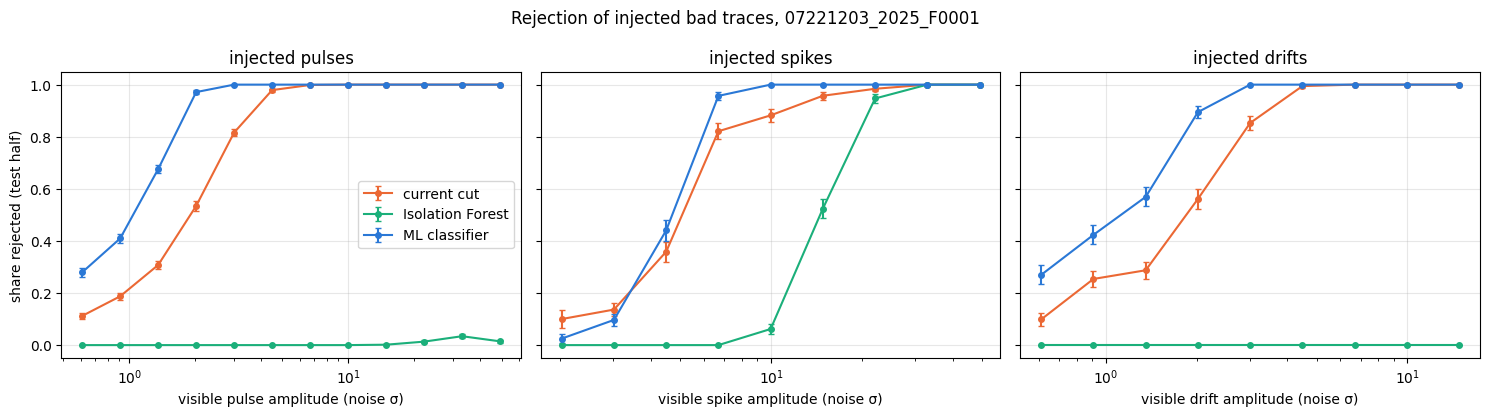

In [13]:
# Injected test set, kept per channel so that the current cut (channel-specific thresholds) can be applied.
inj_test = {}          # key -> (X, kind, amp)
rng_te = np.random.default_rng(2026)
for kind, (lo, hi) in TEST_AMPS.items():
    n_each = 1500
    ev = rng_te.choice(test_pool, n_each, replace=len(test_pool) < n_each)
    a = np.exp(rng_te.uniform(np.log(lo), np.log(hi), n_each))
    traces, hit, vis = inject(ev, kind, a, rng_te)
    Xk, _ = features_of(traces)
    for key in KEYS:
        prev = inj_test.get(key, (np.empty((0, len(FEATURES))), np.empty(0, str), np.empty(0)))
        inj_test[key] = (np.concatenate([prev[0], Xk[key][hit[key]]]),
                         np.concatenate([prev[1], [kind] * hit[key].sum()]),
                         np.concatenate([prev[2], vis[key][hit[key]]]))

METHODS = {
    "current cut": lambda key, X: current_cut(key, X),
    "Isolation Forest": lambda key, X: iso.decision_function(X) > 0,
    "ML classifier": lambda key, X: clf.predict_proba(X)[:, 1] > 0.5,
}

print("clean acceptance on the test half (seed-good randoms kept):")
clean_acc = {}
for name, accept in METHODS.items():
    kept = [accept(key, X_all[key][seed_good[key] & ~is_train_event & IS_RANDOM]) for key in KEYS]
    clean_acc[name] = np.concatenate(kept).mean()
    print(f"  {name:<18}{clean_acc[name]:6.1%}")

print()
print("mean of_trig (OF amplitude at the trigger / sigma_A) of the accepted randoms; pure noise gives 0:")
print(f"{'channel':<9}" + "".join(f"{n:>22}" for n in ["current cut", "Isolation Forest", "ML classifier", "seed good randoms"]))
for key in KEYS:
    row = ""
    for sel in (CUR_GOOD[key], ISO_GOOD[key], ML_GOOD[key], seed_good[key] & IS_RANDOM):
        v = feats[key]["of_trig"][sel]
        row += f"{v.mean():>14.2f} ± {v.std(ddof=1) / np.sqrt(len(v)):<5.2f}"
    print(f"{NAME[key]:<9}{row}")

AMP_BINS = np.geomspace(0.5, 60, 13)
centres = np.sqrt(AMP_BINS[1:] * AMP_BINS[:-1])
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, kind in zip(axes, TEST_AMPS):
    for name, accept in METHODS.items():
        rej, amp_all = [], []
        for key in KEYS:
            X, kd, a = inj_test[key]
            m = kd == kind
            rej.append(~accept(key, X[m])); amp_all.append(a[m])
        rej = np.concatenate(rej); amp_all = np.concatenate(amp_all)
        b = np.digitize(amp_all, AMP_BINS) - 1
        eff = np.array([rej[b == i].mean() if np.any(b == i) else np.nan for i in range(len(centres))])
        n_b = np.array([(b == i).sum() for i in range(len(centres))])
        err = np.sqrt(eff * (1 - eff) / np.maximum(n_b, 1))
        ax.errorbar(centres, eff, yerr=err, marker="o", ms=4, lw=1.5, capsize=2, color=COLOUR[name], label=name)
        print(f"{kind:>6} {name:<18} rejected overall {rej.mean():6.1%}")
    ax.set_xscale("log"); ax.set_xlabel(f"visible {kind} amplitude (noise σ)")
    ax.set_title(f"injected {kind}s"); ax.grid(alpha=0.3)
axes[0].set_ylabel("share rejected (test half)"); axes[0].legend()
fig.suptitle(f"Rejection of injected bad traces, {DUMP}", fontsize=12)
fig.tight_layout(); plt.savefig(FIG / f"ml-noise-injection-rejection-{DUMP}.png", dpi=110); plt.show()

ROC AUC, test seeds vs injections >= 3 sigma: ML classifier 0.9894, Isolation Forest 0.6484


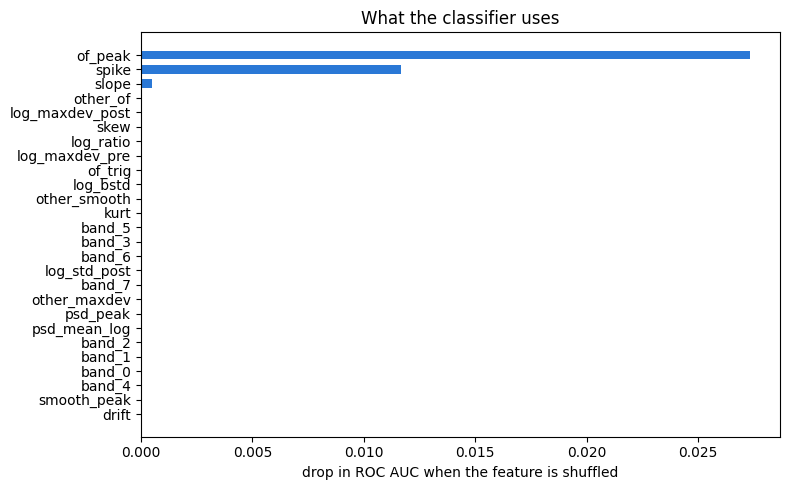

In [14]:
# A single-number summary of how well each method separates the test seeds from the test injections (ROC AUC),
# for the two methods that give a score. The current cut is a yes/no cut and has no curve.
y_eval, s_ml, s_iso = [], [], []
for key in KEYS:
    Xg = X_all[key][seed_good[key] & ~is_train_event & IS_RANDOM]
    Xb = inj_test[key][0][inj_test[key][2] >= 3]           # injections with a visible amplitude of 3 sigma and more
    Xe = np.concatenate([Xg, Xb])
    y_eval.append(np.r_[np.ones(len(Xg)), np.zeros(len(Xb))])
    s_ml.append(clf.predict_proba(Xe)[:, 1]); s_iso.append(iso.decision_function(Xe))
y_eval = np.concatenate(y_eval)
print(f"ROC AUC, test seeds vs injections >= 3 sigma: ML classifier {roc_auc_score(y_eval, np.concatenate(s_ml)):.4f}, "
      f"Isolation Forest {roc_auc_score(y_eval, np.concatenate(s_iso)):.4f}")

# Which features the classifier leans on (permutation importance on a sample of the training set)
from sklearn.inspection import permutation_importance
sample = RNG.choice(len(X_tr), min(6000, len(X_tr)), replace=False)
imp = permutation_importance(clf, X_tr[sample], y_tr[sample], n_repeats=5, random_state=0, scoring="roc_auc")
order = np.argsort(imp.importances_mean)[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh([FEATURES[i] for i in order][::-1], imp.importances_mean[order][::-1], color="#2a78d6", height=0.6)
ax.set_xlabel("drop in ROC AUC when the feature is shuffled"); ax.set_title("What the classifier uses")
fig.tight_layout(); plt.show()

### 4.1 Where the methods disagree

The interesting traces are the ones the methods disagree on. Below: traces the **ML classifier accepts but the current cut rejects** (good noise the current method throws away, if the classifier is right) and traces the **current cut accepts but the classifier rejects** (contamination the current method lets in, if the classifier is right). Look at them: this is the check by eye that the numbers above cannot give.

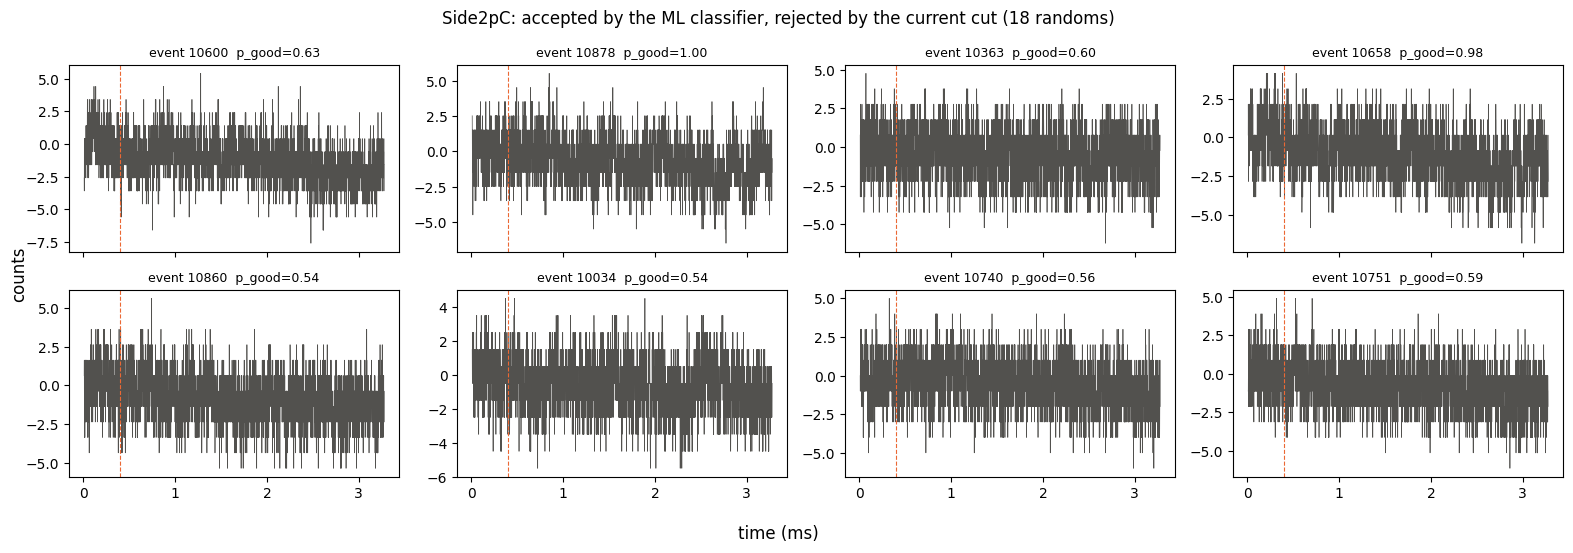

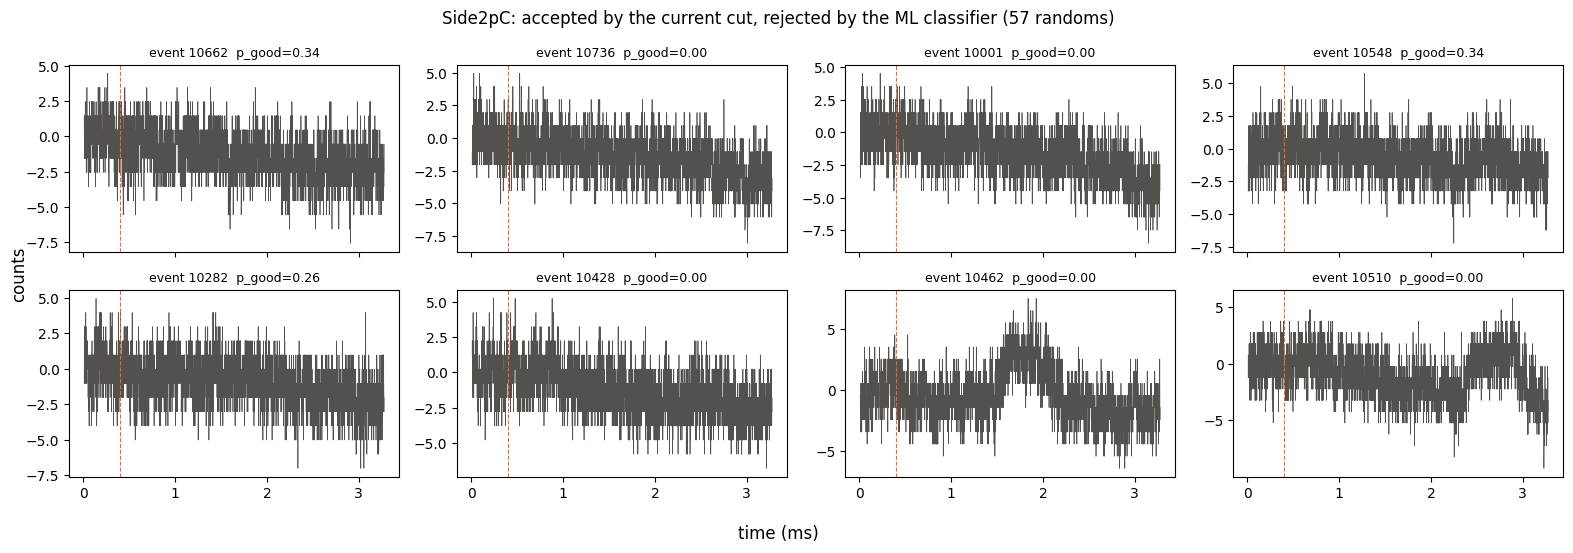

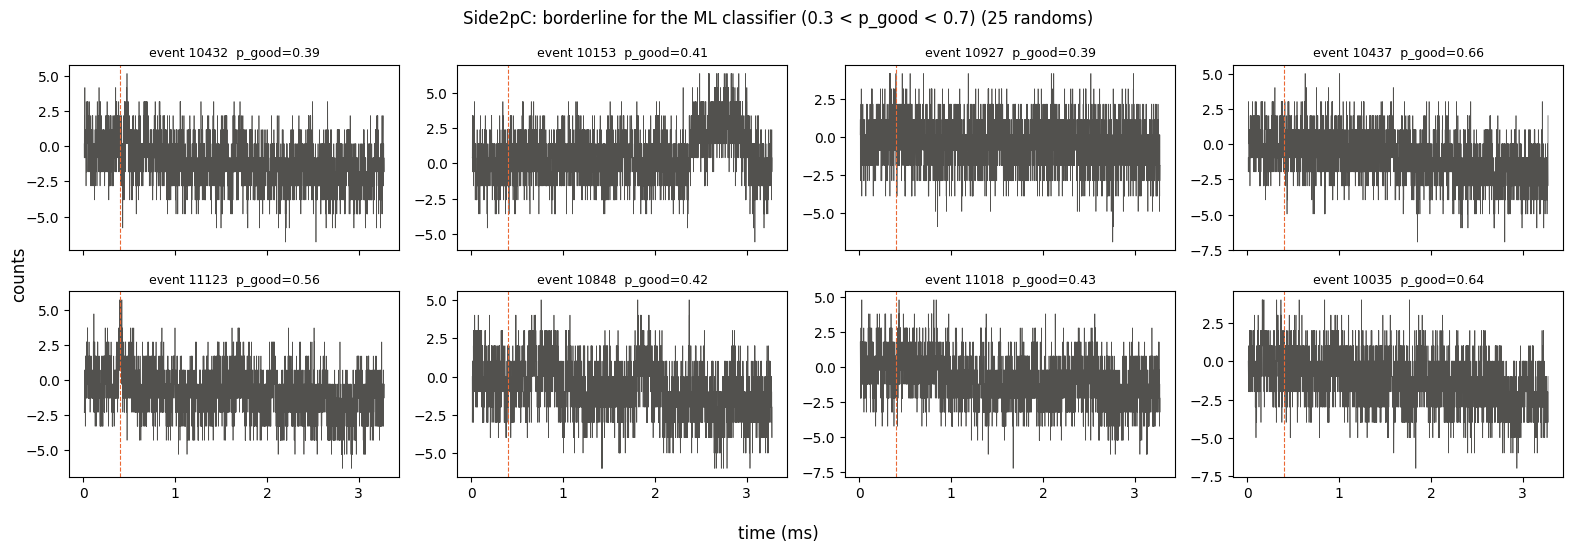

In [15]:
def plot_examples(key, mask, title, n=8):
    rows = np.flatnonzero(mask)
    if len(rows) == 0:
        print(f"{title}: none"); return
    rows = RNG.choice(rows, min(n, len(rows)), replace=False)
    fig, axes = plt.subplots(2, 4, figsize=(16, 5.5), sharex=True)
    for ax, r in zip(axes.flat, rows):
        ax.plot(t_ms, raw_traces[key][r], lw=0.5, color="#52514e")
        ax.set_title(f"event {event_numbers[r]}  p_good={P_GOOD[key][r]:.2f}", fontsize=9)
        ax.axvline(PRETRIGGER * SAMPLE_PERIOD_S * 1e3, color="#eb6834", lw=0.8, ls="--")
    for ax in axes.flat[len(rows):]:
        ax.axis("off")
    fig.suptitle(f"{NAME[key]}: {title} ({mask.sum()} randoms)", fontsize=12)
    fig.supxlabel("time (ms)"); fig.supylabel("counts")
    fig.tight_layout(); plt.show()

key_show = KEYS[0]
plot_examples(key_show, ML_GOOD[key_show] & ~CUR_GOOD[key_show], "accepted by the ML classifier, rejected by the current cut")
plot_examples(key_show, ~ML_GOOD[key_show] & CUR_GOOD[key_show], "accepted by the current cut, rejected by the ML classifier")
plot_examples(key_show, (P_GOOD[key_show] > 0.3) & (P_GOOD[key_show] < 0.7), "borderline for the ML classifier (0.3 < p_good < 0.7)")

## 5. The noise PSD template

For each channel, the template is the mean one-sided PSD of the accepted randoms, with its standard error (std / √N at every bin). The **robust reference** is the bin-by-bin median of the per-trace PSDs of the ML-accepted traces divided by ln 2: for pure Gaussian noise each per-trace PSD bin is exponentially distributed, whose mean is median / ln 2, and a median is hardly moved by a few contaminated traces. A template that sits above the reference at low frequency carries contamination.

**Optimal-filter resolution.** With the pulse shape $s$ (peak 1) and its transform $S_k$, the OF amplitude of a trace $v$ is
$$\hat A = \frac{\sum_k \mathrm{Re}(S_k^* V_k)/J_k}{\sum_k |S_k|^2/J_k},$$
(sum over the positive-frequency bins, DC excluded, no time shift) and for noise with one-sided PSD $J$ its expected spread is $\sigma_A = \sqrt{\frac{N}{4\,\Delta t \sum_k |S_k|^2/J_k}}$ (counts of pulse amplitude). Two numbers per template:

- **predicted** $\sigma_A$, from the template itself;
- **realised** $\sigma_A$: the spread of $\hat A$ over held-out noise traces (true amplitude 0), traces *not* used to build the template. The events are split in two halves at random; the templates come from half A and the realised resolution is measured on the seed-good randoms of half B (section 3: within 3 spreads of typical noise in every time-domain, OF and cross-channel feature), so every template is judged on the same traces, picked by neither method's own cut.

A better noise template gives a smaller realised resolution (the filter weights the frequencies better), and a predicted value that agrees with the realised one (the template describes the real noise).

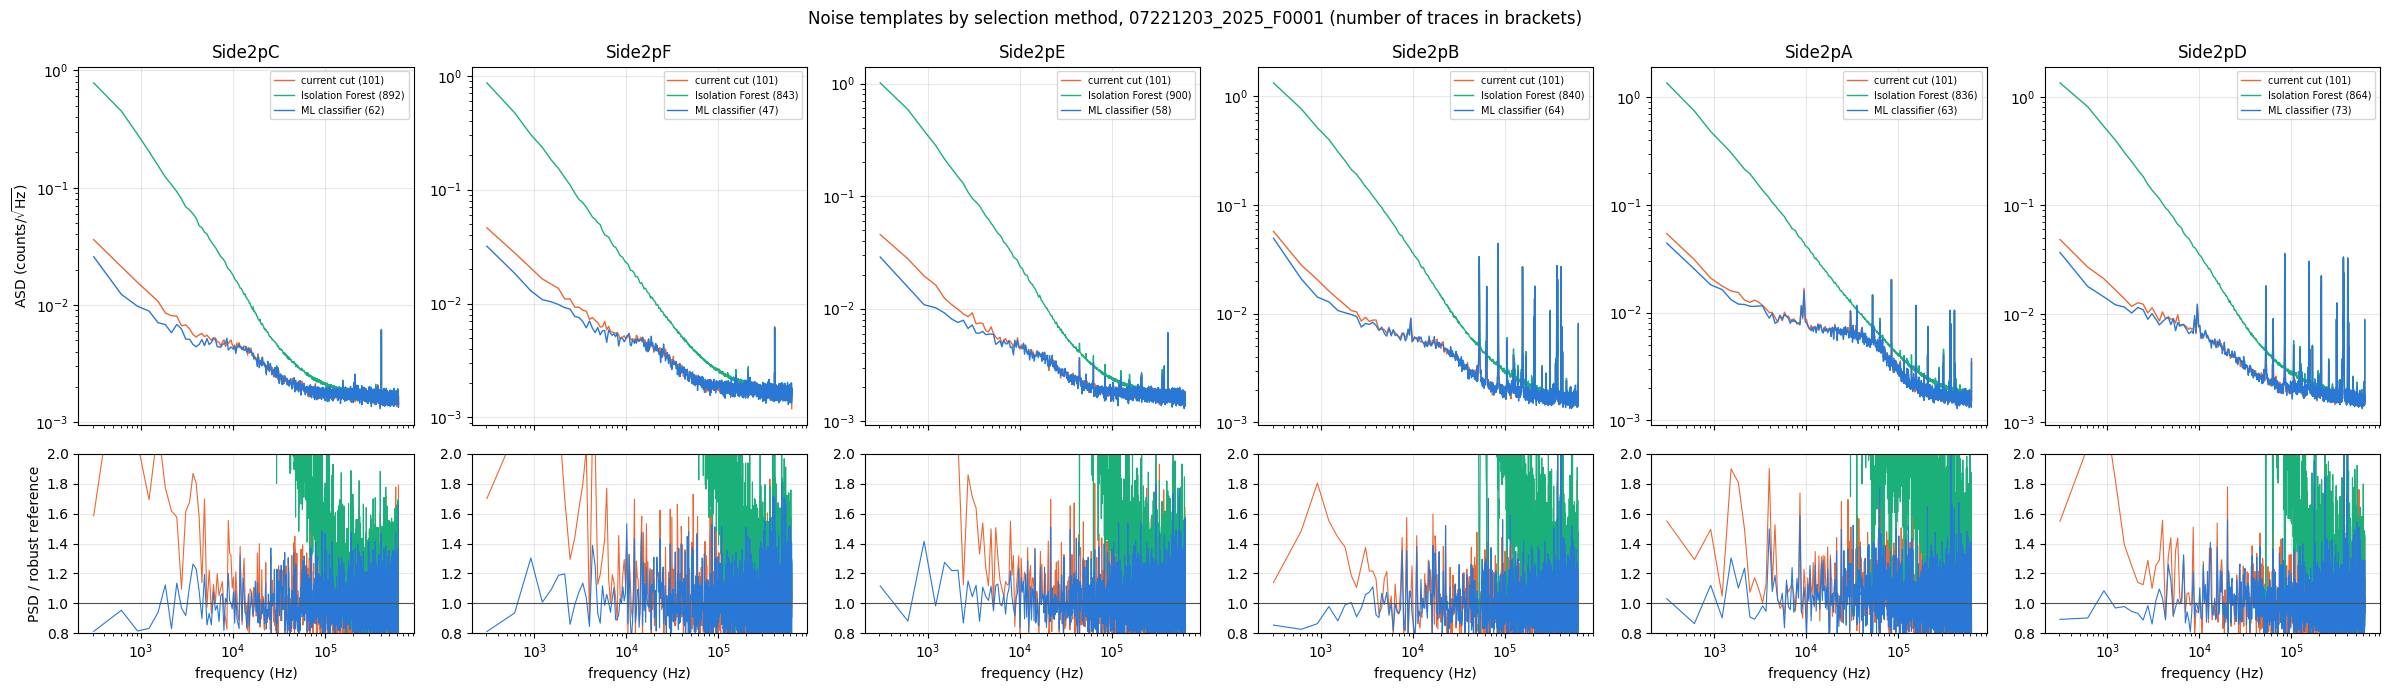

Template / robust reference, mean over each band:
channel  method               0.3-3 kHz    3-30 kHz  30-300 kHz    >300 kHz  median SEM/mean
Side2pC  current cut              1.789       1.083       0.990       0.987            0.098
Side2pC  Isolation Forest       713.821      29.563       1.407       1.031            0.035
Side2pC  ML classifier            0.857       0.980       0.993       0.990            0.124
Side2pF  current cut              1.911       1.173       0.985       0.992            0.098
Side2pF  Isolation Forest       536.494      32.305       1.917       1.084            0.037
Side2pF  ML classifier            0.913       1.024       0.977       0.986            0.141
Side2pE  current cut              2.705       1.147       0.998       0.995            0.098
Side2pE  Isolation Forest      1161.932      50.428       1.750       1.065            0.036
Side2pE  ML classifier            1.083       1.016       0.990       0.991            0.128
Side2pB  current cut

In [16]:
def psd_of_rows(key, rows, chunk=1000):
    x = raw_traces[key]
    return np.concatenate([one_sided_psd(x[rows[i:i + chunk]]) for i in range(0, len(rows), chunk)]) if len(rows) else np.empty((0, len(FREQS)))


SELECTIONS = {"current cut": CUR_GOOD, "Isolation Forest": ISO_GOOD, "ML classifier": ML_GOOD}
PSD_GOOD = {key: psd_of_rows(key, np.flatnonzero(ML_GOOD[key])) for key in KEYS}   # per-trace PSDs, reused below
TEMPLATE = {}
for key in KEYS:
    TEMPLATE[key] = {}
    for name, sel in SELECTIONS.items():
        p = PSD_GOOD[key] if name == "ML classifier" else psd_of_rows(key, np.flatnonzero(sel[key]))
        TEMPLATE[key][name] = (p.mean(axis=0), p.std(axis=0, ddof=1) / np.sqrt(len(p)), len(p))
    TEMPLATE[key]["robust reference"] = (np.median(PSD_GOOD[key], axis=0) / np.log(2), None, len(PSD_GOOD[key]))

fig, axes = plt.subplots(2, len(KEYS), figsize=(4 * len(KEYS), 7), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
for j, key in enumerate(KEYS):
    ref = TEMPLATE[key]["robust reference"][0]
    for name in SELECTIONS:
        mean, sem, n = TEMPLATE[key][name]
        axes[0, j].loglog(FREQS[1:], np.sqrt(mean[1:]), lw=1, color=COLOUR[name], label=f"{name} ({n})")
        r = mean[1:] / ref[1:]
        axes[1, j].semilogx(FREQS[1:], r, lw=0.8, color=COLOUR[name])
    axes[0, j].set_title(NAME[key]); axes[0, j].legend(fontsize=7); axes[0, j].grid(alpha=0.3, which="major")
    axes[1, j].axhline(1, color="#52514e", lw=0.8); axes[1, j].set_ylim(0.8, 2.0); axes[1, j].grid(alpha=0.3)
    axes[1, j].set_xlabel("frequency (Hz)")
axes[0, 0].set_ylabel("ASD (counts/$\\sqrt{\\mathrm{Hz}}$)"); axes[1, 0].set_ylabel("PSD / robust reference")
fig.suptitle(f"Noise templates by selection method, {DUMP} (number of traces in brackets)", fontsize=12)
fig.tight_layout(); plt.savefig(FIG / f"ml-noise-templates-{DUMP}.png", dpi=110); plt.show()

print("Template / robust reference, mean over each band:")
show_bands = [("0.3-3 kHz", 300, 3e3), ("3-30 kHz", 3e3, 3e4), ("30-300 kHz", 3e4, 3e5), (">300 kHz", 3e5, np.inf)]
print(f"{'channel':<9}{'method':<18}" + "".join(f"{b[0]:>12}" for b in show_bands) + f"{'median SEM/mean':>17}")
for key in KEYS:
    ref = TEMPLATE[key]["robust reference"][0]
    for name in SELECTIONS:
        mean, sem, n = TEMPLATE[key][name]
        vals = [mean[(FREQS >= lo) & (FREQS < hi)].mean() / ref[(FREQS >= lo) & (FREQS < hi)].mean() for _, lo, hi in show_bands]
        print(f"{NAME[key]:<9}{name:<18}" + "".join(f"{v:>12.3f}" for v in vals) + f"{np.median(sem[1:] / mean[1:]):>17.3f}")

In [17]:
def of_weights(key, J):
    S = np.fft.rfft(PULSE[key])
    w = np.conj(S[KBINS]) / J[KBINS]
    norm = np.sum(np.abs(S[KBINS]) ** 2 / J[KBINS])
    sigma_pred = np.sqrt(N_SAMP / (4 * SAMPLE_PERIOD_S * norm))
    return w, norm, sigma_pred


def of_amplitudes(key, rows, J, chunk=2000):
    w, norm, _ = of_weights(key, J)
    x = raw_traces[key]
    out = []
    for i in range(0, len(rows), chunk):
        V = np.fft.rfft(x[rows[i:i + chunk]], axis=1)[:, KBINS]
        out.append(np.real(V @ w) / norm)
    return np.concatenate(out)


half_A = RNG.random(n_events) < 0.5
print(f"{'channel':<9}{'method':<18}{'traces (A)':>11}{'predicted':>11}{'realised (B)':>14}{'realised/pred':>15}")
OF_RESULT = {}
for key in KEYS:
    eval_rows = np.flatnonzero(~half_A & seed_good[key] & IS_RANDOM)
    for name, sel in SELECTIONS.items():
        rows_A = np.flatnonzero(half_A & sel[key])
        J = psd_of_rows(key, rows_A).mean(axis=0)
        _, _, pred = of_weights(key, J)
        real = of_amplitudes(key, eval_rows, J).std(ddof=1)
        OF_RESULT[(key, name)] = (len(rows_A), pred, real)
        print(f"{NAME[key]:<9}{name:<18}{len(rows_A):>11}{pred:>11.3f}{real:>14.3f}{real / pred:>15.3f}")
    print(f"{'':<9}(realised on the {len(eval_rows)} seed-good randoms of half B)")

# A check of the OF itself: a pulse of known amplitude injected into held-out noise comes back with that amplitude.
key = KEYS[0]
rows = np.flatnonzero(~half_A & ML_GOOD[key])[:300]
J = TEMPLATE[key]["ML classifier"][0]
A_noise = of_amplitudes(key, rows, J)
saved = raw_traces[key][rows].copy()
raw_traces[key][rows] += 20 * PULSE[key]
A_hat = of_amplitudes(key, rows, J)
raw_traces[key][rows] = saved
print(f"OF check on {NAME[key]} ({len(rows)} accepted randoms of half B): noise alone {A_noise.mean():.2f} +- {A_noise.std(ddof=1):.2f}, "
      f"with an injected amplitude of 20: {A_hat.mean():.2f}; difference {np.mean(A_hat - A_noise):.3f} (should be 20)")

channel  method             traces (A)  predicted  realised (B)  realised/pred
Side2pC  current cut                54      0.644         0.511          0.793
Side2pC  Isolation Forest          424      3.202         2.505          0.782
Side2pC  ML classifier              27      0.480         0.529          1.102
         (realised on the 20 seed-good randoms of half B)


Side2pF  current cut                54      0.861         0.610          0.708
Side2pF  Isolation Forest          404      5.541         3.203          0.578
Side2pF  ML classifier              18      0.632         0.631          0.998
         (realised on the 16 seed-good randoms of half B)
Side2pE  current cut                54      0.813         0.648          0.797


Side2pE  Isolation Forest          431      4.407         4.578          1.039
Side2pE  ML classifier              26      0.564         0.569          1.008
         (realised on the 19 seed-good randoms of half B)
Side2pB  current cut                54      0.915         0.852          0.932
Side2pB  Isolation Forest          401      7.833         6.856          0.875
Side2pB  ML classifier              29      0.772         0.821          1.062
         (realised on the 21 seed-good randoms of half B)


Side2pA  current cut                54      1.123         1.077          0.959
Side2pA  Isolation Forest          397      9.604        10.291          1.071
Side2pA  ML classifier              28      0.960         1.131          1.178
         (realised on the 22 seed-good randoms of half B)
Side2pD  current cut                54      0.959         0.974          1.016


Side2pD  Isolation Forest          413      6.686         8.879          1.328
Side2pD  ML classifier              33      0.759         0.965          1.271
         (realised on the 22 seed-good randoms of half B)
OF check on Side2pC (35 accepted randoms of half B): noise alone -0.43 +- 0.46, with an injected amplitude of 20: 19.57; difference 20.000 (should be 20)


## 6. Local noise templates

One template per dump assumes the noise does not change during the dump. Two ways to test it:

1. **Blocks**: the dump is cut into consecutive blocks of events, and a template is made from the accepted traces of each block. For each block and each of 24 log-spaced frequency bands, the difference from the dump-wide template is divided by its standard error; if the noise is the same everywhere, these *pulls* scatter with a spread of 1, and $\chi^2$ per band is about 1.
2. **Rolling template**: every accepted trace gets its own template, the mean PSD of the $K$ accepted traces nearest to it in time (itself excluded). Its realised OF resolution is compared with that of the dump-wide template built the same way (all accepted traces but itself). If the noise changes during the dump, the rolling template is better matched and gives a smaller realised resolution.

C:\Users\gspil\AppData\Local\Temp\ipykernel_58224\538672129.py:15: RuntimeWarning: Mean of empty slice.
  tmpl = np.array([psd[blk == b].mean(axis=0) for b in range(N_BLOCKS)])
C:\Users\gspil\anaconda3\envs\darkmatter_cli_env\Lib\site-packages\numpy\_core\_methods.py:137: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(
C:\Users\gspil\anaconda3\envs\darkmatter_cli_env\Lib\site-packages\numpy\_core\_methods.py:223: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
C:\Users\gspil\anaconda3\envs\darkmatter_cli_env\Lib\site-packages\numpy\_core\_methods.py:181: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
C:\Users\gspil\anaconda3\envs\darkmatter_cli_env\Lib\site-packages\numpy\_core\_methods.py:212: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(
C:\Users\gspil\AppData\Local\Temp\ipykernel_58224\538672129.py:25: Runt

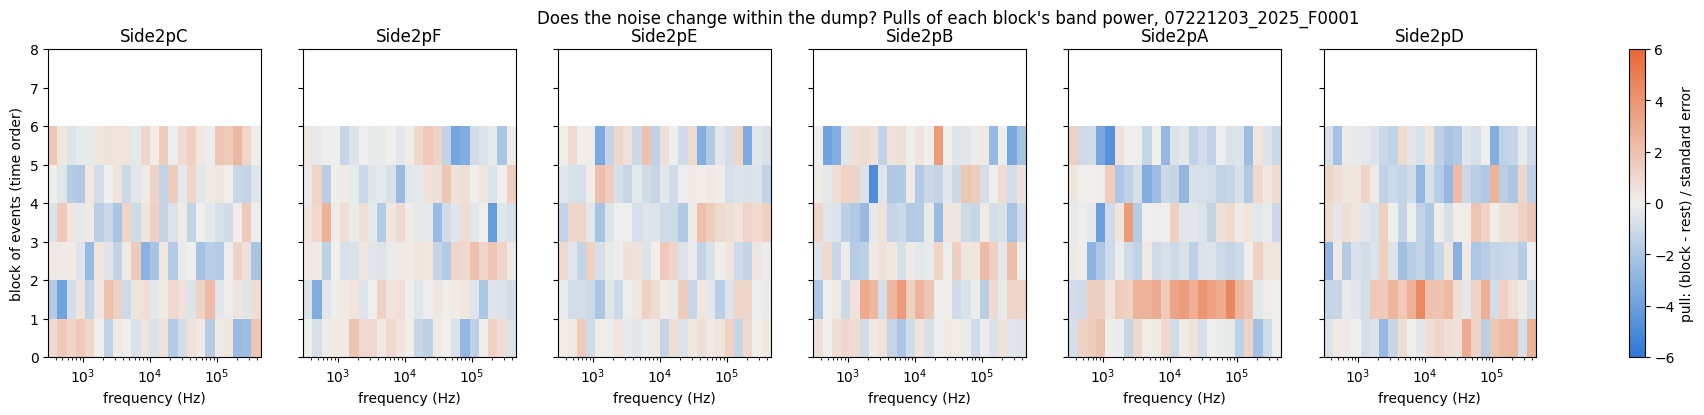

channel    chi2/dof all blocks  largest |pull|  worst band (Hz)              traces per block
Side2pC                    nan             nan              306  [7, 15, 13, 10, 12, 4, 0, 1]
Side2pF                    nan             nan              306   [5, 13, 10, 5, 11, 3, 0, 0]
Side2pE                    nan             nan              306   [5, 14, 13, 7, 14, 4, 0, 1]
Side2pB                    nan             nan              306   [7, 15, 15, 8, 15, 4, 0, 0]
Side2pA                    nan             nan              306   [9, 12, 17, 8, 13, 4, 0, 0]
Side2pD                    nan             nan              306   [7, 16, 18, 8, 18, 5, 0, 1]


In [18]:
N_BLOCKS = 8
block_edges = np.linspace(0, n_events, N_BLOCKS + 1).astype(int)
block_of_event = np.searchsorted(block_edges, np.arange(n_events), side="right") - 1
COARSE_EDGES = np.geomspace(FREQS[1], FREQS[-1], 25)
coarse_bins = [(FREQS >= lo) & (FREQS < hi) for lo, hi in zip(COARSE_EDGES[:-1], COARSE_EDGES[1:])]
coarse_bins = [b for b in coarse_bins if b.sum() > 0]
coarse_f = np.array([FREQS[b].mean() for b in coarse_bins])

LOCAL = {}            # key -> (block templates (blocks, bins), block sems, counts)
PULLS = {}
for key in KEYS:
    rows_good = np.flatnonzero(ML_GOOD[key])
    blk = block_of_event[rows_good]
    psd = PSD_GOOD[key]
    tmpl = np.array([psd[blk == b].mean(axis=0) for b in range(N_BLOCKS)])
    sems = np.array([psd[blk == b].std(axis=0, ddof=1) / np.sqrt((blk == b).sum()) for b in range(N_BLOCKS)])
    counts = np.array([(blk == b).sum() for b in range(N_BLOCKS)])
    LOCAL[key] = (tmpl, sems, counts)
    # pulls per block and coarse band, against the dump-wide mean of the *other* blocks (independent)
    pulls = np.zeros((N_BLOCKS, len(coarse_bins)))
    for b in range(N_BLOCKS):
        p_in = psd[blk == b]; p_out = psd[blk != b]
        for i, cb in enumerate(coarse_bins):
            a = p_in[:, cb].mean(axis=1); c = p_out[:, cb].mean(axis=1)       # per-trace band power
            pulls[b, i] = (a.mean() - c.mean()) / np.sqrt(a.var(ddof=1) / len(a) + c.var(ddof=1) / len(c))
    PULLS[key] = pulls

fig, axes = plt.subplots(1, len(KEYS), figsize=(4 * len(KEYS), 4), sharey=True)
for ax, key in zip(np.atleast_1d(axes), KEYS):
    im = ax.pcolormesh(COARSE_EDGES[:len(coarse_bins) + 1], np.arange(N_BLOCKS + 1), PULLS[key],
                       cmap=DIVERGING, vmin=-6, vmax=6, shading="flat")
    ax.set_xscale("log"); ax.set_xlabel("frequency (Hz)"); ax.set_title(NAME[key])
np.atleast_1d(axes)[0].set_ylabel("block of events (time order)")
fig.colorbar(im, ax=axes, label="pull: (block - rest) / standard error")
fig.suptitle(f"Does the noise change within the dump? Pulls of each block's band power, {DUMP}", fontsize=12)
plt.savefig(FIG / f"ml-noise-local-pulls-{DUMP}.png", dpi=110, bbox_inches="tight"); plt.show()

print(f"{'channel':<9}{'chi2/dof all blocks':>21}{'largest |pull|':>16}{'worst band (Hz)':>17}{'traces per block':>30}")
for key in KEYS:
    p = PULLS[key]
    b, i = np.unravel_index(np.argmax(np.abs(p)), p.shape)
    print(f"{NAME[key]:<9}{(p ** 2).mean():>21.2f}{np.abs(p).max():>16.1f}{coarse_f[i]:>17.0f}{str(LOCAL[key][2].tolist()):>30}")

In [19]:
# Diagnostic (Run 76): how many randoms, and of what trigger type, are in each block of events?
for b in range(N_BLOCKS):
    m = block_of_event == b
    print(f"block {b}: events {block_edges[b]} to {block_edges[b + 1] - 1} (event numbers {event_numbers[m][0]} to {event_numbers[m][-1]}), "
          f"{IS_RANDOM[m].sum()} randoms, {(~IS_RANDOM[m]).sum()} other")


block 0: events 0 to 188 (event numbers 10000 to 10188), 189 randoms, 0 other
block 1: events 189 to 378 (event numbers 10189 to 10378), 190 randoms, 0 other
block 2: events 379 to 567 (event numbers 10379 to 10567), 189 randoms, 0 other
block 3: events 568 to 757 (event numbers 10568 to 10757), 190 randoms, 0 other
block 4: events 758 to 947 (event numbers 10758 to 10947), 190 randoms, 0 other
block 5: events 948 to 1136 (event numbers 10948 to 11155), 54 randoms, 135 other
block 6: events 1137 to 1326 (event numbers 11156 to 11345), 2 randoms, 188 other
block 7: events 1327 to 1516 (event numbers 11346 to 11569), 4 randoms, 186 other


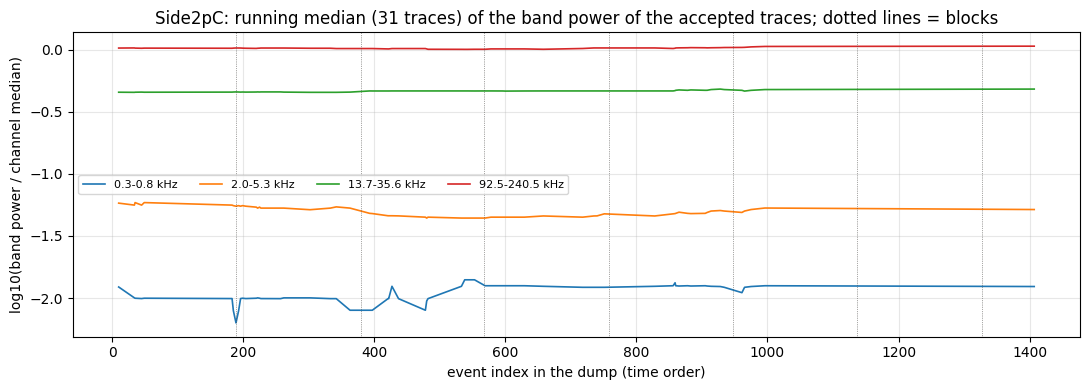

In [20]:
# Band power against time: a running median over the accepted traces, one curve per band, for one channel.
key = KEYS[0]
rows_good = np.flatnonzero(ML_GOOD[key])
fig, ax = plt.subplots(figsize=(11, 4))
for k, (lo, hi) in enumerate(zip(BAND_EDGES[:-1], BAND_EDGES[1:])):
    if k % 2:
        continue
    v = feats[key][f"band_{k}"][rows_good]
    w = 31
    run = np.array([np.median(v[max(0, i - w // 2): i + w // 2 + 1]) for i in range(len(v))])
    ax.plot(rows_good, run, lw=1.2, label=f"{lo / 1e3:.1f}-{hi / 1e3:.1f} kHz")
for e in block_edges[1:-1]:
    ax.axvline(e, color="#52514e", lw=0.5, ls=":")
ax.set_xlabel("event index in the dump (time order)"); ax.set_ylabel("log10(band power / channel median)")
ax.set_title(f"{NAME[key]}: running median (31 traces) of the band power of the accepted traces; dotted lines = blocks")
ax.legend(fontsize=8, ncol=4); ax.grid(alpha=0.3)
fig.tight_layout(); plt.show()

In [21]:
# Rolling (local) template versus dump-wide template, both leave-one-out, judged by the realised OF resolution.
K_VALUES = [30, 100, 300]


def of_on_own_template(key, psd_rows, J_rows, rows):
    # OF amplitude of each trace with its own template J_rows[i] (vectorised over traces).
    S = np.fft.rfft(PULSE[key])[KBINS]
    V = np.fft.rfft(raw_traces[key][rows], axis=1)[:, KBINS]
    J = J_rows[:, KBINS]
    num = np.real(np.conj(S) * V / J).sum(axis=1)
    norm = (np.abs(S) ** 2 / J).sum(axis=1)
    return num / norm, np.sqrt(N_SAMP / (4 * SAMPLE_PERIOD_S * norm))


print(f"{'channel':<9}{'template':<22}{'realised':>10}{'mean predicted':>16}")
ROLLING = {}
for key in KEYS:
    rows_good = np.flatnonzero(ML_GOOD[key])
    psd = PSD_GOOD[key].astype(np.float64)
    n = len(psd)
    total = psd.sum(axis=0)
    J_glob = (total[None, :] - psd) / (n - 1)
    res = {}
    A, pred = [], []
    for i0 in range(0, n, 1000):
        a, p = of_on_own_template(key, psd[i0:i0 + 1000], J_glob[i0:i0 + 1000], rows_good[i0:i0 + 1000])
        A.append(a); pred.append(p)
    res["dump-wide (LOO)"] = (np.concatenate(A).std(ddof=1), np.concatenate(pred).mean())
    del J_glob
    c = np.vstack([np.zeros(psd.shape[1]), np.cumsum(psd, axis=0)])
    for K in [k for k in K_VALUES if k < n - 1]:
        A, pred = [], []
        for i0 in range(0, n, 1000):
            i = np.arange(i0, min(i0 + 1000, n))
            lo = np.clip(i - K // 2, 0, n - K - 1); hi = lo + K + 1           # K neighbours + the trace itself
            J = (c[hi] - c[lo] - psd[i]) / K
            a, p = of_on_own_template(key, None, J, rows_good[i])
            A.append(a); pred.append(p)
        res[f"rolling K={K}"] = (np.concatenate(A).std(ddof=1), np.concatenate(pred).mean())
    ROLLING[key] = res
    for name, (real, pr) in res.items():
        print(f"{NAME[key]:<9}{name:<22}{real:>10.4f}{pr:>16.4f}")

channel  template                realised  mean predicted
Side2pC  dump-wide (LOO)           0.4503          0.4791
Side2pC  rolling K=30              0.4470          0.4719
Side2pF  dump-wide (LOO)           0.6051          0.6598
Side2pF  rolling K=30              0.6162          0.6574
Side2pE  dump-wide (LOO)           0.5671          0.5793
Side2pE  rolling K=30              0.5774          0.5741
Side2pB  dump-wide (LOO)           0.7773          0.7762
Side2pB  rolling K=30              0.7932          0.7661
Side2pA  dump-wide (LOO)           0.9008          0.9928
Side2pA  rolling K=30              0.9110          0.9710


Side2pD  dump-wide (LOO)           0.7231          0.7705
Side2pD  rolling K=30              0.7450          0.7650


## 7. Save the templates

One HDF5 file next to this notebook, `noise-templates-ml-<dump>.h5`, readable by an optimal filter without re-running anything:

| where | what |
|---|---|
| file attributes | dump, sample period (and that it is assumed), conventions, units, settings |
| `/frequency_hz` | frequency bins (Hz) |
| `/event_numbers`, `/block_edges` | the dump's events in order; the event-index edges of the local blocks |
| `/channels/det<d>_ch<c>/psd_ml`, `psd_ml_sem` | the ML template and its standard error |
| `.../psd_current`, `psd_current_sem` | the current-cut template, for comparison |
| `.../psd_local`, `psd_local_sem`, `local_counts` | one template per block |
| `.../pulse_shape` | the averaged pulse shape (peak 1) |
| `.../p_good`, `is_random` | the classifier's $p_\mathrm{good}$ for every event, and which events are randoms |

In [22]:
OUT = Path(f"noise-templates-ml-{DUMP}.h5")
with h5py.File(OUT, "w") as f:
    f.attrs["dump"] = DUMP
    f.attrs["sample_period_s"] = SAMPLE_PERIOD_S
    f.attrs["sample_period_note"] = "0.8 us, the Run 76 phonon readout (registry: DCRC_RUN76)"
    f.attrs["psd_convention"] = "one-sided: S = (2 dt / N) |X_k|^2, no factor 2 at DC and Nyquist; pretrigger-mean subtracted (500 samples), 10 glitch samples dropped"
    f.attrs["units"] = "psd: counts^2/Hz"
    f.attrs["samples_per_trace"] = N_SAMP
    f.attrs["classifier"] = "HistGradientBoostingClassifier on time/frequency/OF/cross-channel features, trained on seeds + injected pulses/spikes/drifts over all events; good = p_good > 0.5; templates from the accepted randoms (cuts.randoms)"
    f.attrs["current_cut"] = "clean_randoms of Note 9: randoms & excursion_band [0.5, 0.7) & log10(bstd) < 0.5 on Side2pA, the event list used for every channel"
    f.create_dataset("frequency_hz", data=FREQS)
    f.create_dataset("event_numbers", data=event_numbers)
    f.create_dataset("block_edges", data=block_edges)
    g_all = f.create_group("channels")
    for key in KEYS:
        g = g_all.create_group(f"det{key[0]}_ch{key[1]}")
        g.attrs.update(detector=key[0], channel=key[1], name=NAME[key], noise_sigma_counts=NOISE_SIGMA[key])
        for label, name in (("ml", "ML classifier"), ("current", "current cut")):
            mean, sem, n = TEMPLATE[key][name]
            g.create_dataset(f"psd_{label}", data=mean); g.create_dataset(f"psd_{label}_sem", data=sem)
            g.attrs[f"n_{label}"] = n
        g.create_dataset("psd_local", data=LOCAL[key][0]); g.create_dataset("psd_local_sem", data=LOCAL[key][1])
        g.create_dataset("local_counts", data=LOCAL[key][2])
        g.create_dataset("pulse_shape", data=PULSE[key])
        g.create_dataset("p_good", data=P_GOOD[key].astype(np.float32))
        g.create_dataset("is_random", data=IS_RANDOM)

with h5py.File(OUT, "r") as f:
    for key in KEYS:
        assert np.allclose(f["channels"][f"det{key[0]}_ch{key[1]}"]["psd_ml"][:], TEMPLATE[key]["ML classifier"][0])
    print(f"{OUT} written and read back: {len(f['channels'])} channels, {len(f['frequency_hz'])} bins, {OUT.stat().st_size / 1e6:.1f} MB")

noise-templates-ml-07221203_2025_F0001.h5 written and read back: 6 channels, 2044 bins, 1.7 MB


## 8. What the results say, and what to do next

The results of this run, and what I read in them, are written up in my note (`notes/src/ml-noise-selection-r76.md`).

Questions to answer from the outputs:

- **Use of the data.** How many traces per channel does the classifier accept compared with the current cut (section 3.3)? How much smaller is the template's standard error (section 5, `median SEM/mean`)?
- **Classification quality.** Clean acceptance and the rejection curves (section 4): from what pulse amplitude (in noise σ) is each method above 90% rejection? Are the disagreements of 4.1 really good noise or really contaminated, by eye?
- **Template quality.** Does the current-cut template sit above the robust reference at low frequency (contamination)? Which template gives the smallest *realised* OF resolution on held-out traces, and is it close to its *predicted* one?
- **Local templates.** Are the block pulls consistent with 1 (no change in time), or are some bands or blocks far out? Does the rolling template beat the dump-wide one in realised resolution? If not, a single template per dump is enough for this dump; if so, by how much, and at which $K$?

Next steps:

- Repeat on other dumps of the series (the result here is one dump).
- A semi-supervised refinement: hand-label a few hundred of the borderline traces of 4.1, add them to the training set, and see how much the numbers move.
- Use time-shifted OF (a fit of the pulse start) for the realised resolution, as a real analysis would.